# Code to create Fig. 3.1 of "Mountain Glaciers and Snowpack. In: Overshoot and the Cryosphere: Averting Global Meltdown. The Implications of Temperature Overshoot, Peak and Decline for the Cryosphere" (https://zenodo.org/records/24084311)

**Methods**

Glacier projections were made with the Open Global Glacier Model (OGGM) for six example glaciers also used in Schuster et al. (2025). Each glacier starts from its modelled state in the year 2000. This means the simulations include the ice loss already committed by past warming: most glaciers are not in balance with today's climate and continue to shrink even if warming stops.

The temperature pathways are the idealised ICCI overshoot scenarios, digitised from the ICCI overshoot graphic. For each year from 2000 to 2550, the difference between a scenario's global warming and its 2000–2024 average (about 1.0°C above pre-industrial) is used as a temperature change. The glacier mass balance for that year is computed separately for each of the 25 years of ERA5 climate from 2000 to 2024, shifted by this temperature change, and then averaged. Real seasonal and year-to-year climate variations thus shape the average mass balance, but individual warm or cold years do not appear in the results. All scenarios share the same warming up to 2024 and diverge from 2025 onwards. Stabilising at 1.5°C, for example, corresponds to a climate about 0.5°C warmer than the 2000–2024 average, while the very high overshoot peaks about 2°C above it. The “High Overshoot” scenario reconverges to 1.5°C at year 2220, and the “Very High Overshoot” Scenario reconverges at year 2250. 

The global mean temperature change is applied directly at each glacier (no regional amplification--> Global warming is applied 1:1 at the glacier → conservative response!!!), and no precipitation change is applied. The results therefore illustrate how glaciers respond to temperature overshoot, rather than predicting the future of these specific glaciers.

Additional methods explained in the report. 

---
*code from Lilian Schuster (Vrije Universiteit Brussel), visualisations and the digitisation of the idealised overshoot scenarios (see "digitization_validation_overlay_update.png") were done with some help by the Artificial Intelligence "Claude Opus 5.5"*

---

**Cite as:**

code to create Fig. 3.1 of https://zenodo.org/records/24084311: Kang, S., Kaser, G., Llambi, L. D., Maharjan, A., Marshall, A., Schuster, L., Tielidze, L., and Zhang,
Q. (2026). Mountain Glaciers and Snowpack. In: Overshoot and the Cryosphere: Averting Global Meltdown. The Implications of
Temperature Overshoot, Peak and Decline for the Cryosphere. [Kirkham, J.D., Pearson, P., Garbe, J., Hancock, S., Imdieke, A. (eds.)].
International Cryosphere Climate Initiative. DOI: 10.5281/zenodo.23477467*






# Create Fig. 3.1b (idealised individual glacier response to the idealised overshoot scenarios within the ICCI UNEP Overshoot report using the OGGM glacier model)

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context('notebook') 
import xarray as xr
import salem
import numpy as np
import pandas as pd
import geopandas as gpd
import json

import oggm.cfg
from oggm import utils, workflow, tasks, graphics
from oggm.sandbox.edu import run_constant_climate_with_bias
# OGGM options
oggm.cfg.initialize(logging_level='WARNING')

2026-11-13 15:41:23: oggm.cfg: Reading default parameters from the OGGM `params.cfg` configuration file.
2026-11-13 15:41:23: oggm.cfg: Multiprocessing switched OFF according to the parameter file.
2026-11-13 15:41:23: oggm.cfg: Multiprocessing: using all available processors (N=8)


In [2]:
# need ERA5 because we need historical climate until end of 2024!!!
ERA5_base_url = 'https://cluster.klima.uni-bremen.de/~oggm/gdirs/oggm_v1.6/L3-L5_files/2025.6/elev_bands/ERA5/per_glacier_spinup/'

In [3]:
# Local working directory (where OGGM will write its output)
oggm.cfg.PATHS['working_dir'] = utils.gettempdir('OGGM_overshoot_idealised')#, reset=True)

In [4]:
plt.rcParams["pdf.use14corefonts"] = False  # don't convert text to path
plt.rcParams['pdf.fonttype']=42 # do nout line text?

In [5]:
# use the same example glaciers as in Schuster et al. (2025)
rgi_ids = ['RGI60-11.01450', 'RGI60-13.54431', 'RGI60-16.01251', 'RGI60-01.13696', 'RGI60-03.01710', 'RGI60-04.06187']
#rgi_ids = ['RGI60-11.01450',  'RGI60-03.01710']

In [6]:
gdirs= workflow.init_glacier_directories(rgi_ids,from_prepro_level=5, prepro_base_url=ERA5_base_url)


2026-11-13 15:41:24: oggm.workflow: init_glacier_directories from prepro level 5 on 6 glaciers.
2026-11-13 15:41:24: oggm.workflow: Execute entity tasks [gdir_from_prepro] on 6 glaciers
2026-11-13 15:41:24: oggm.workflow: WARNING: you are trying to run an entity task on 6 glaciers with multiprocessing turned off. OGGM will run faster with multiprocessing turned on.


In [7]:
pd_temp_scenario = pd.read_csv('digitized_overshoot_scenarios_update.csv', index_col='year')

In [8]:
pd_temp_scenario = pd_temp_scenario.drop(columns='paris_target_1.5C_reference')

overshoot_colors = {
    "very_high_overshoot_3.0C_peak":       "#A64C79",  # purple/maroon
    "high_overshoot_2.2C_peak":            "#CB0000",  # red
    "limited_overshoot_1.7C_peak":         "#F1C232",  # gold/yellow
    "stabilization_1.5C_no_overshoot":     "#E69138",  # orange
    "paris_target_1.5C_reference":         "#125A9E",  # blue
}

In [9]:
# beginning of year 2000 till end of 2024 --> corresponds to 25 years 
# I need an uneven number, for the run_constant_climate apporach ... so I can't go until end of 2025
pd_temp_ch_scenario_2000_2025 = pd_temp_scenario - pd_temp_scenario.loc[2000:2024].mean()

In [10]:
# forcing has to be "relative to 2000-2025" to work with the constant climate bias function of OGGM 
pd_temp_ch_scenario_2000_2025

,very_high_overshoot_3.0C_peak,high_overshoot_2.2C_peak,limited_overshoot_1.7C_peak,stabilization_1.5C_no_overshoot
year,,,,
2000,-0.256368,-0.256368,-0.256368,-0.256368
2001,-0.245768,-0.245768,-0.245768,-0.245768
2002,-0.232168,-0.232168,-0.232168,-0.232168
2003,-0.215868,-0.215868,-0.215868,-0.215868
2004,-0.197068,-0.197068,-0.197068,-0.197068
...,...,...,...,...
2546,0.471232,0.471232,-0.163768,0.471232
2547,0.471232,0.471232,-0.163768,0.471232
2548,0.471232,0.471232,-0.163768,0.471232


### Do the idealised simulations

In [13]:
load = True
# this takes some time 
if load:
    for gdir in gdirs:
        for scen in pd_temp_ch_scenario_2000_2025.columns:
            run_constant_climate_with_bias(gdir, temp_bias_ts=pd_temp_ch_scenario_2000_2025[scen],
                                           y0=2012, halfsize=12, # use 2012-12 (2000) until 2012+12 (2024) as the constant climate period...
                                           climate_filename ='climate_historical', output_filesuffix=f'_idealised_{scen}',
                                           init_model_yr=2000,
                                           init_model_filesuffix='_spinup_historical')


### Visualise the idealised simulations

In [22]:
scenarios_order = ['stabilization_1.5C_no_overshoot', 'limited_overshoot_1.7C_peak',
                   'high_overshoot_2.2C_peak', 'very_high_overshoot_3.0C_peak']

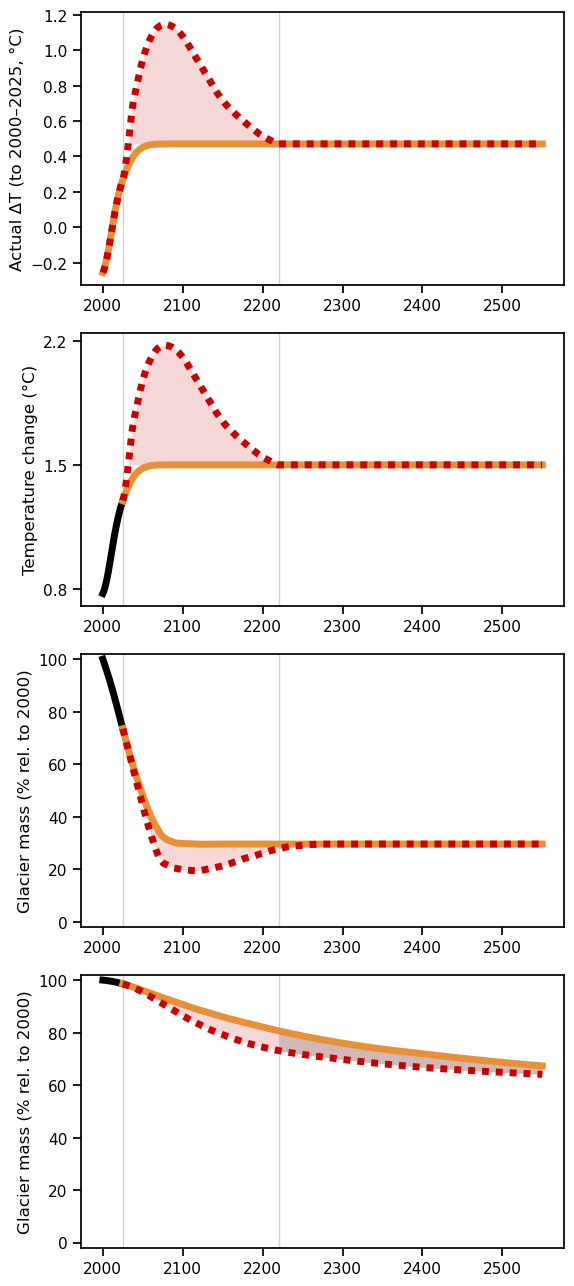

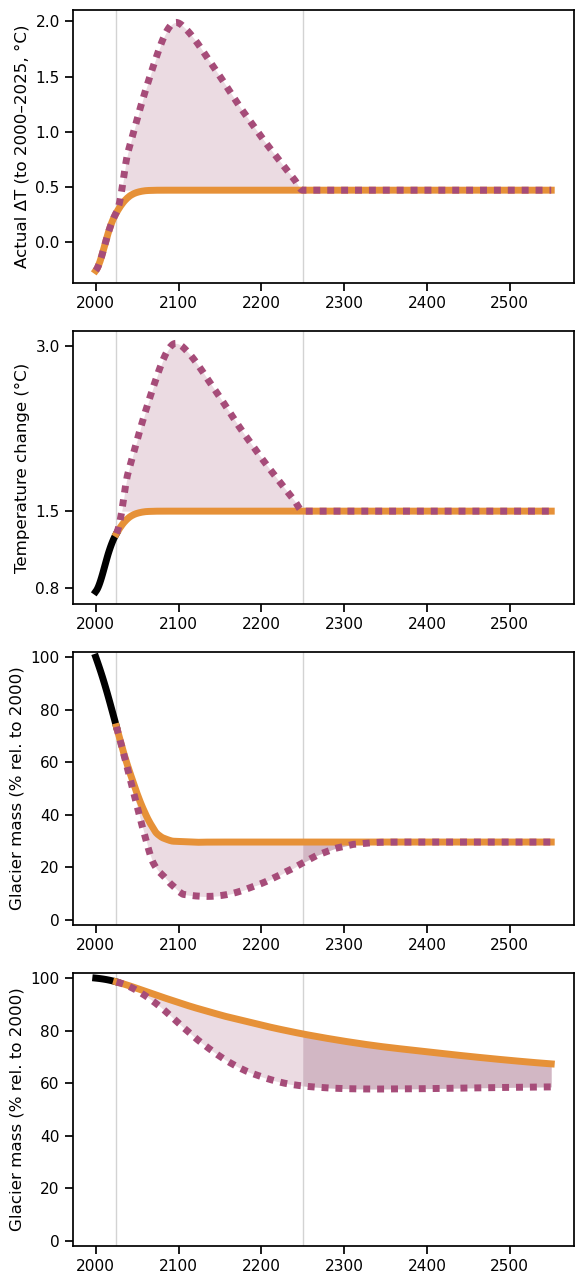

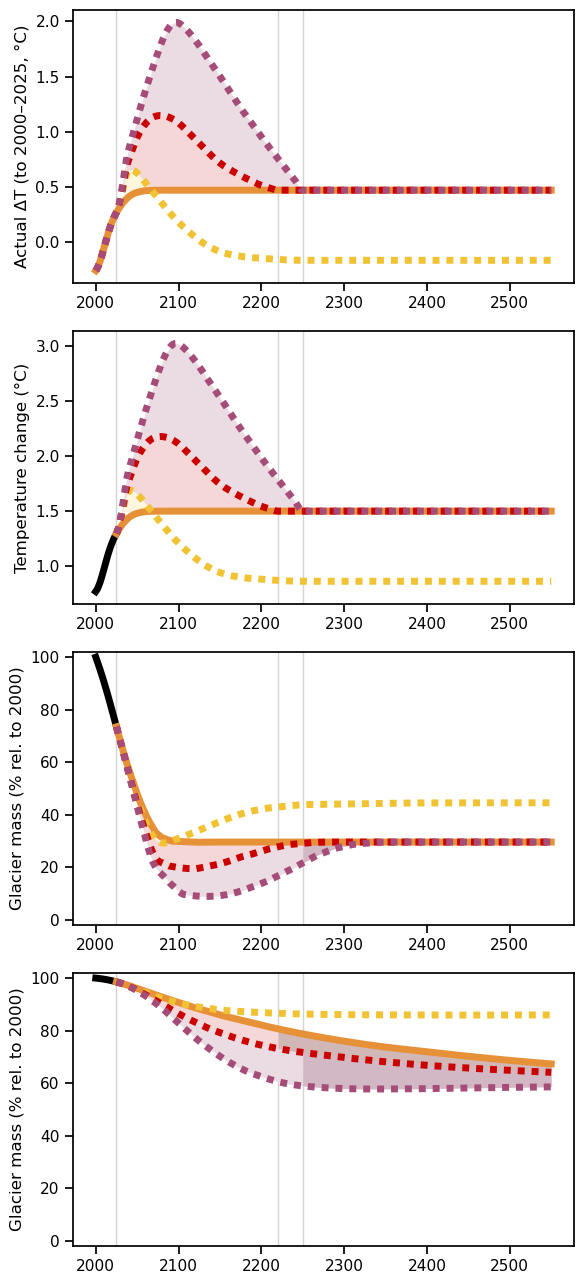

In [23]:
# ---------------------------------------------------------------------------
# style settings
# ---------------------------------------------------------------------------
lw_temp = 5
lw_glac = 5

stab = 'stabilization_1.5C_no_overshoot'
# overshoot pathways dotted (square dots, like the reference figure)
ls_overshoot = (0, (1, 1))
# year in which the temperature of the scenario is back at 1.5C
reconv_year = {'high_overshoot_2.2C_peak': 2220,
               'very_high_overshoot_3.0C_peak': 2250}
# light fill: overshoot phase (fill colours of the ICCI figure)
fill_light = {'very_high_overshoot_3.0C_peak': '#EBDBE2',
              'high_overshoot_2.2C_peak': '#F5D7D7',
              'limited_overshoot_1.7C_peak': '#FFF6DD'}
# darker fill: legacy phase (same lightness/saturation as in the reference figure)
fill_legacy = {'very_high_overshoot_3.0C_peak': '#D2B7C4',
               'high_overshoot_2.2C_peak': '#D2B7B7'}
# largest overshoot first, so the smaller fills are drawn on top
fill_order = ['very_high_overshoot_3.0C_peak', 'high_overshoot_2.2C_peak',
              'limited_overshoot_1.7C_peak']


def ls_of(scen):
    return '-' if scen == stab else ls_overshoot


def mark_years(ax, scens):
    if scens == 'stab_very_high':
        yrs = [2025, 2250]
    elif scens == 'stab_high':
        yrs = [2025, 2220]
    else:
        yrs = [2025, 2220, 2250]
    for yr in yrs:
        ax.axvline(yr, color='lightgrey', lw=1, zorder=0)


def shade_temperature(ax, df, scenarios):
    """Fill between each overshoot pathway and the 1.5C level (where above it)."""
    ref = df[stab].iloc[-1]  # 1.5C in the units of df (also works for the anomaly)
    for scen in [s for s in fill_order if s in scenarios]:
        y = df[scen]
        ax.fill_between(df.index, ref, y, where=(y > ref).values, interpolate=True,
                        color=fill_light[scen], lw=0, zorder=1)


def shade_glacier(ax, vol, scenarios):
    """Fill between stabilization and overshoot glacier mass (where lower):
    light during the overshoot phase, darker after the temperature reconverged."""
    base = vol[stab]
    t = vol.index.values
    for scen in [s for s in fill_order if s in scenarios]:
        y = vol[scen]
        lower = (y < base).values
        ry = reconv_year.get(scen)
        if ry is None:
            phases = [(lower, fill_light[scen])]
        else:
            phases = [(lower & (t <= ry), fill_light[scen]),
                      (lower & (t >= ry), fill_legacy[scen])]
        for where, c in phases:
            ax.fill_between(t, base, y, where=where, interpolate=True,
                            color=c, lw=0, zorder=1)


def glacier_volumes(gdir, scenarios):
    """Glacier mass in % of 2000 for all scenarios (index: year)."""
    out = {}
    for scen in list(dict.fromkeys([stab, *scenarios])):
        with xr.open_dataset(gdir.get_filepath('model_diagnostics',
                                               filesuffix=f'_idealised_{scen}')) as _ds:
            _ds = _ds.load()
            out[scen] = pd.Series(100 * _ds.volume_m3.values / _ds.volume_m3.sel(time=2000).item(),
                                  index=_ds.time.values)
    return pd.DataFrame(out).loc[2000:2550]


for scens in ['stab_high', 'stab_very_high', 'all']:
    if scens == 'stab_high':
        scenarios = [stab, 'high_overshoot_2.2C_peak']
    elif scens == 'stab_very_high':
        scenarios = [stab, 'very_high_overshoot_3.0C_peak']
    elif scens == 'all':
        scenarios = scenarios_order
    plt.figure(figsize=(6, 13))

    # temperature anomaly
    ax = plt.subplot(4, 1, 1)
    shade_temperature(ax, pd_temp_ch_scenario_2000_2025, scenarios)
    for scen in scenarios:
        ax.plot(pd_temp_ch_scenario_2000_2025.index, pd_temp_ch_scenario_2000_2025[scen],
                color=overshoot_colors[scen], lw=lw_temp, ls=ls_of(scen), zorder=2)
    ax.set_ylabel('Actual ΔT (to 2000–2025, °C)')
    mark_years(ax, scens)

    # temperature change rel. to pre-industrial
    ax = plt.subplot(4, 1, 2)
    shade_temperature(ax, pd_temp_scenario, scenarios)
    ax.plot(pd_temp_scenario.loc[:2025].index, pd_temp_scenario[stab].loc[:2025],
            color='k', lw=lw_temp, zorder=2)
    for scen in scenarios:
        ax.plot(pd_temp_scenario.loc[2025:].index, pd_temp_scenario[scen].loc[2025:],
                color=overshoot_colors[scen], lw=lw_temp, ls=ls_of(scen), zorder=2)
    if scens == 'stab_very_high':
        ax.set_yticks([0.8, 1.5, 3.0])
    elif scens == 'stab_high':
        ax.set_yticks([0.8, 1.5, 2.2])
    ax.set_ylabel('Temperature change (°C)')
    mark_years(ax, scens)

    # glacier mass
    for j, gdir in enumerate([gdirs[0], gdirs[-2]]):
        ax = plt.subplot(4, 1, 3 + j)
        vol = glacier_volumes(gdir, scenarios)
        shade_glacier(ax, vol.loc[2025:], scenarios)
        ax.plot(vol.loc[:2025].index, vol[stab].loc[:2025], color='k', lw=lw_glac, zorder=2)
        for scen in scenarios:
            ax.plot(vol.loc[2025:].index, vol[scen].loc[2025:],
                    color=overshoot_colors[scen], lw=lw_glac, ls=ls_of(scen), zorder=2)
        ax.set_ylabel('Glacier mass (% rel. to 2000)')
        mark_years(ax, scens)
        ax.set_ylim([-2, 102])
    plt.tight_layout()
    plt.savefig(f'idealised_icci_overshoot_scenario_glacier_response_{scens}.pdf')

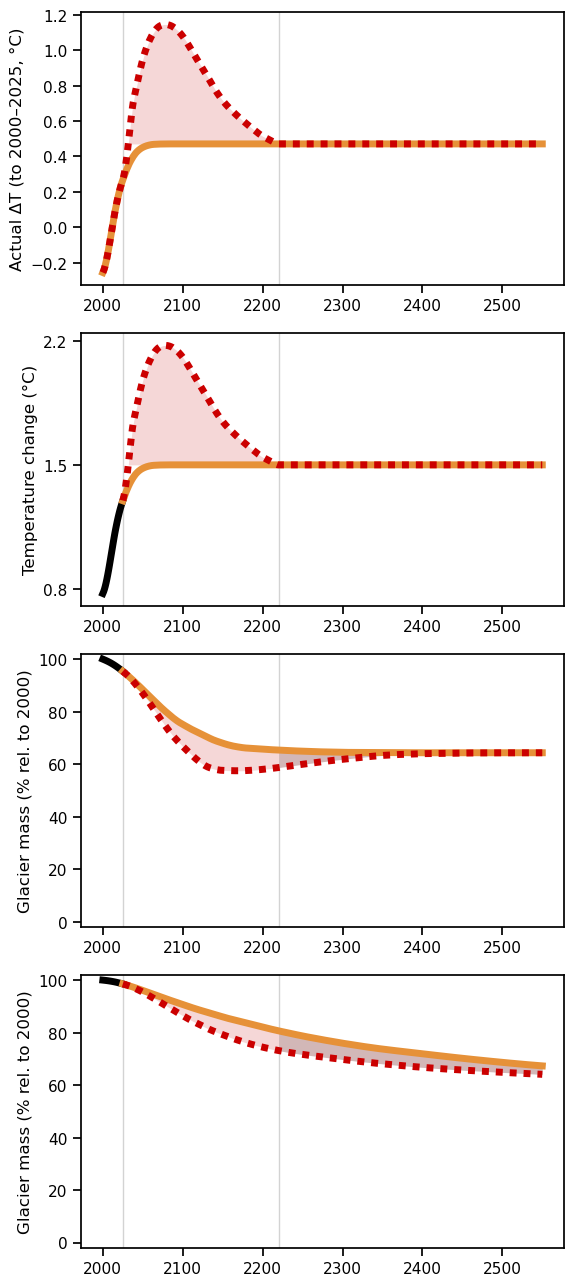

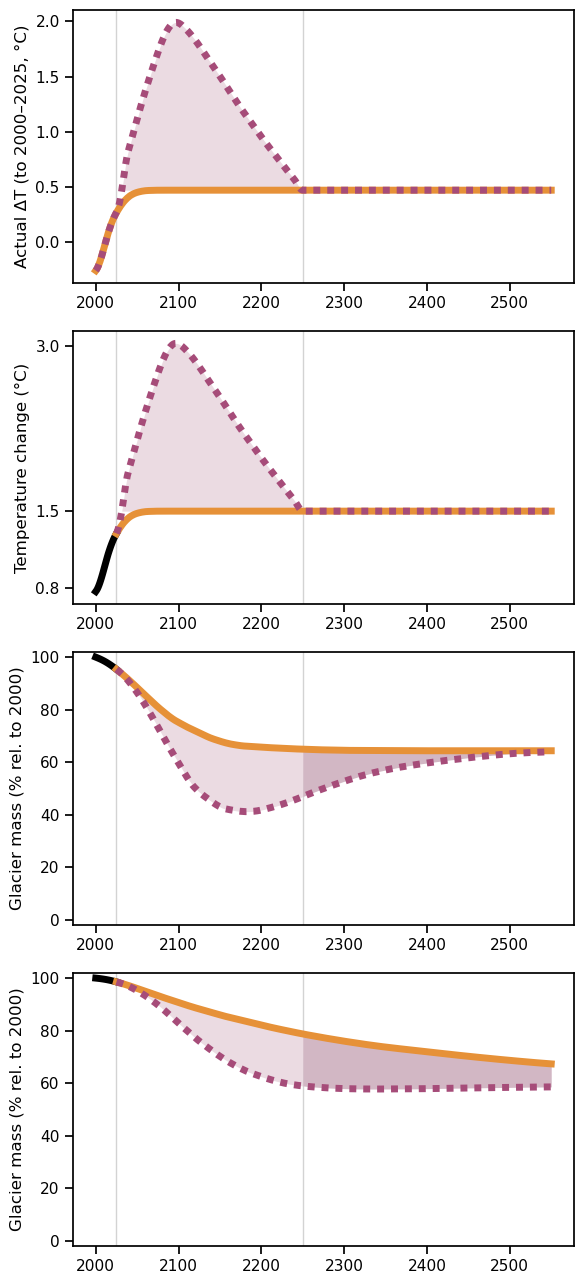

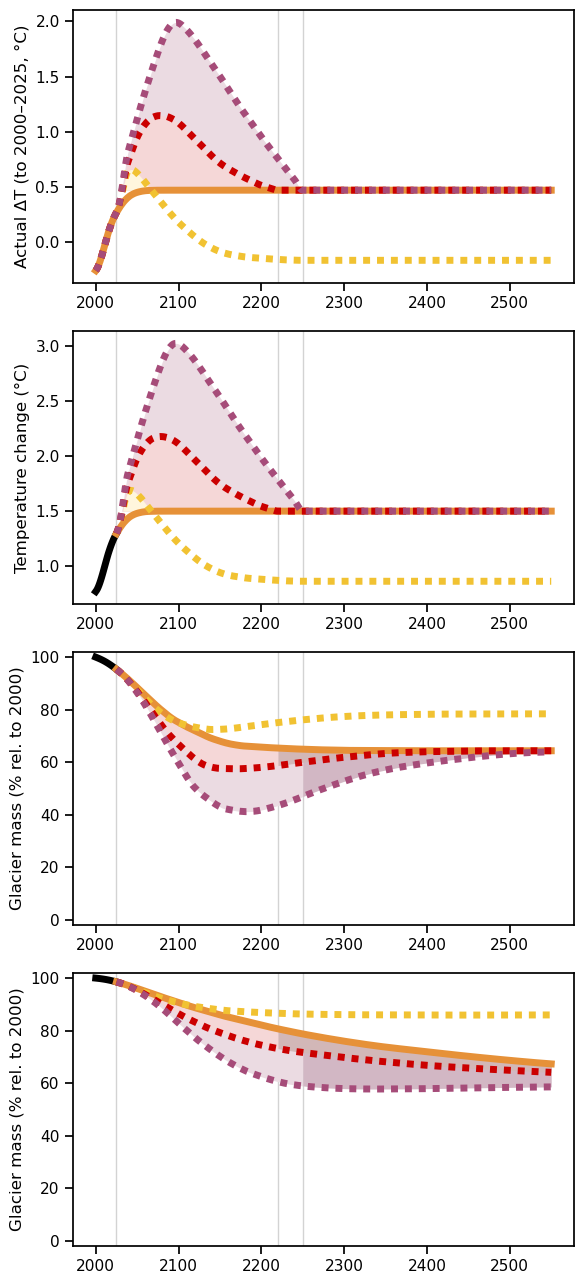

In [28]:
# use another fast-responding glacier as example ... RGI60-13.54431
# Region: 13: Central Asia
# Subregion: 13-02: Pamir (Safed Khirs/W Tarim)     
# Name: Su5X14308A001 Fedchenko

for scens in ['stab_high', 'stab_very_high', 'all']:
    if scens == 'stab_high':
        scenarios = [stab, 'high_overshoot_2.2C_peak']
    elif scens == 'stab_very_high':
        scenarios = [stab, 'very_high_overshoot_3.0C_peak']
    elif scens == 'all':
        scenarios = scenarios_order
    plt.figure(figsize=(6, 13))

    # temperature anomaly
    ax = plt.subplot(4, 1, 1)
    shade_temperature(ax, pd_temp_ch_scenario_2000_2025, scenarios)
    for scen in scenarios:
        ax.plot(pd_temp_ch_scenario_2000_2025.index, pd_temp_ch_scenario_2000_2025[scen],
                color=overshoot_colors[scen], lw=lw_temp, ls=ls_of(scen), zorder=2)
    ax.set_ylabel('Actual ΔT (to 2000–2025, °C)')
    mark_years(ax, scens)

    # temperature change rel. to pre-industrial
    ax = plt.subplot(4, 1, 2)
    shade_temperature(ax, pd_temp_scenario, scenarios)
    ax.plot(pd_temp_scenario.loc[:2025].index, pd_temp_scenario[stab].loc[:2025],
            color='k', lw=lw_temp, zorder=2)
    for scen in scenarios:
        ax.plot(pd_temp_scenario.loc[2025:].index, pd_temp_scenario[scen].loc[2025:],
                color=overshoot_colors[scen], lw=lw_temp, ls=ls_of(scen), zorder=2)
    if scens == 'stab_very_high':
        ax.set_yticks([0.8, 1.5, 3.0])
    elif scens == 'stab_high':
        ax.set_yticks([0.8, 1.5, 2.2])
    ax.set_ylabel('Temperature change (°C)')
    mark_years(ax, scens)

    # glacier mass
    for j, gdir in enumerate([gdirs[1], gdirs[-2]]):
        ax = plt.subplot(4, 1, 3 + j)
        vol = glacier_volumes(gdir, scenarios)
        shade_glacier(ax, vol.loc[2025:], scenarios)
        ax.plot(vol.loc[:2025].index, vol[stab].loc[:2025], color='k', lw=lw_glac, zorder=2)
        for scen in scenarios:
            ax.plot(vol.loc[2025:].index, vol[scen].loc[2025:],
                    color=overshoot_colors[scen], lw=lw_glac, ls=ls_of(scen), zorder=2)
        ax.set_ylabel('Glacier mass (% rel. to 2000)')
        mark_years(ax, scens)
        ax.set_ylim([-2, 102])
    plt.tight_layout()
    plt.savefig(f'idealised_icci_overshoot_scenario_glacier_response_{scens}_fedchenko_glacier_wykeham_glacier_south.pdf')

In [27]:
gdirs[1]

<oggm.GlacierDirectory>
  RGI id: RGI60-13.54431
  Region: 13: Central Asia
  Subregion: 13-02: Pamir (Safed Khirs/W Tarim)     
  Name: Su5X14308A001 Fedchenko
  Glacier type: Glacier
  Terminus type: Land-terminating
  Status: Glacier or ice cap
  Area: 663.729 km2
  Lon, Lat: (72.23385, 38.78024)
  Grid (nx, ny): (514, 648)
  Grid (dx, dy): (200.0, -200.0)

### different glaciers all in one figure

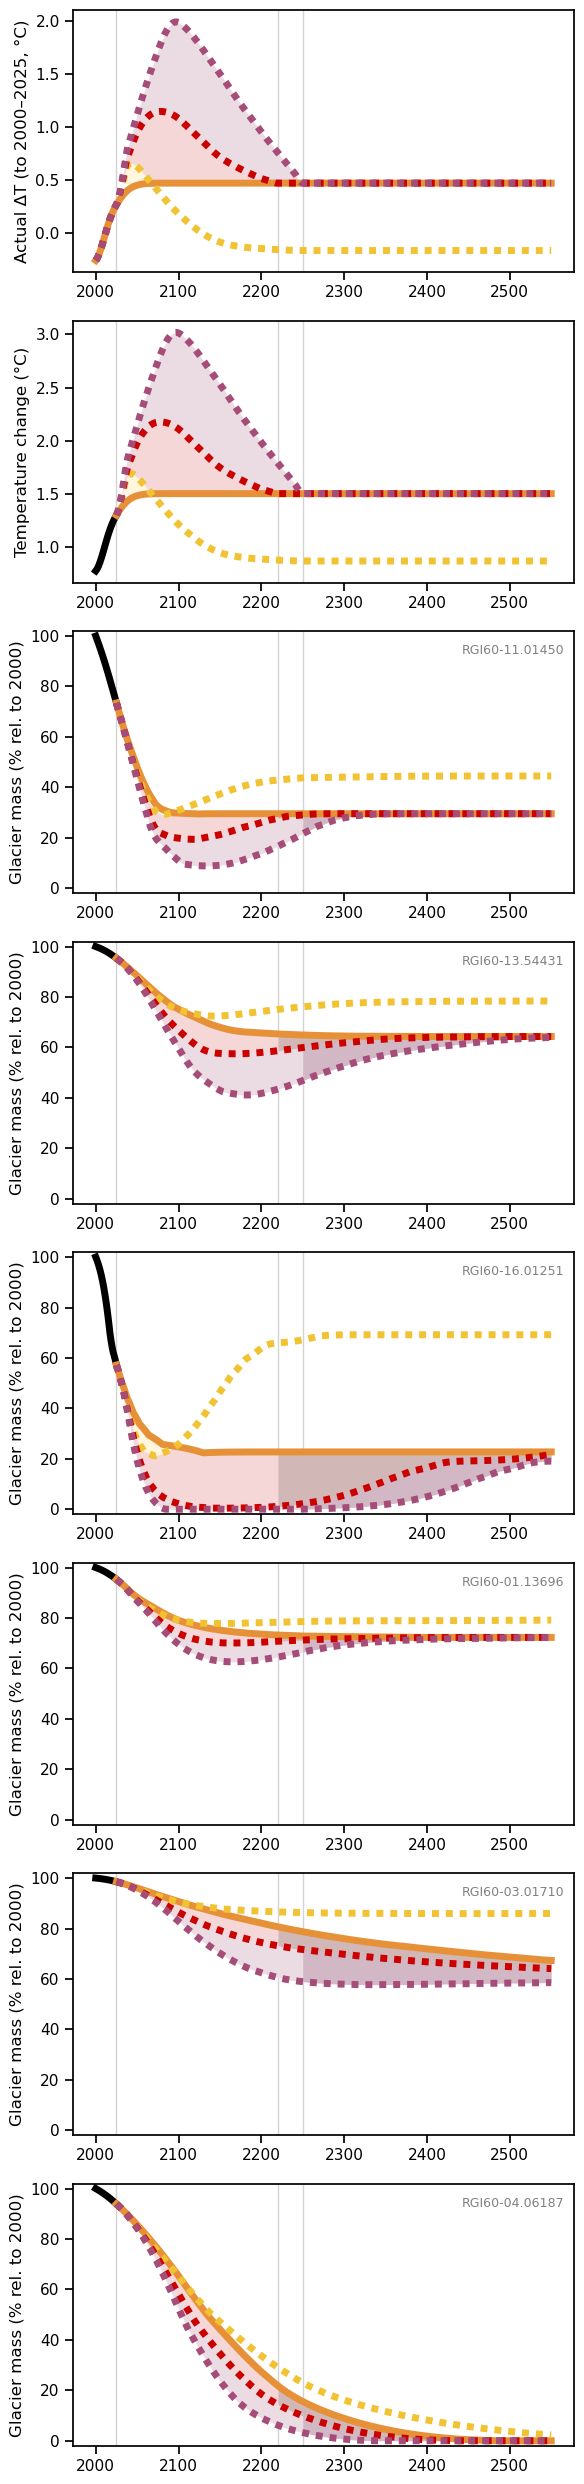

In [24]:

plt.figure(figsize=(6, 25))

# temperature anomaly
ax = plt.subplot(8, 1, 1)
shade_temperature(ax, pd_temp_ch_scenario_2000_2025, scenarios_order)
for scen in scenarios_order:
    ax.plot(pd_temp_ch_scenario_2000_2025.index, pd_temp_ch_scenario_2000_2025[scen],
            color=overshoot_colors[scen], lw=lw_temp, ls=ls_of(scen), zorder=2)
ax.set_ylabel('Actual ΔT (to 2000–2025, °C)')
mark_years(ax, 'all')

# temperature change rel. to pre-industrial
ax = plt.subplot(8, 1, 2)
shade_temperature(ax, pd_temp_scenario, scenarios_order)
ax.plot(pd_temp_scenario.loc[:2025].index, pd_temp_scenario[stab].loc[:2025],
        color='k', lw=lw_temp, zorder=2)
for scen in scenarios_order:
    ax.plot(pd_temp_scenario.loc[2025:].index, pd_temp_scenario[scen].loc[2025:],
            color=overshoot_colors[scen], lw=lw_temp, ls=ls_of(scen), zorder=2)
ax.set_ylabel('Temperature change (°C)')
mark_years(ax, 'all')

# glacier mass, one panel per glacier
for j, gdir in enumerate(gdirs):
    ax = plt.subplot(8, 1, 3 + j)
    ax.text(0.98, 0.95, gdir.rgi_id, transform=ax.transAxes,
            ha='right', va='top', color='grey', fontsize=9)
    vol = glacier_volumes(gdir, scenarios_order)
    shade_glacier(ax, vol.loc[2025:], scenarios_order)
    ax.plot(vol.loc[:2025].index, vol[stab].loc[:2025], color='k', lw=lw_glac, zorder=2)
    for scen in scenarios_order:
        ax.plot(vol.loc[2025:].index, vol[scen].loc[2025:],
                color=overshoot_colors[scen], lw=lw_glac, ls=ls_of(scen), zorder=2)
    ax.set_ylabel('Glacier mass (% rel. to 2000)')
    mark_years(ax, 'all')
    ax.set_ylim([-2, 102])

plt.tight_layout()
plt.savefig('idealised_icci_overshoot_scenario_glacier_response_different glaciers.pdf')

# Create Fig. 3.1a (glacier response timescale map using Zekollari, Schuster et al. data...)

In [7]:
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
from oggm import utils
from matplotlib.image import imread
import pandas as pd

### --> get this data from https://zenodo.org/records/15046588 
pd_gmip3_stats = pd.read_csv('../3_shift_summary_region_characteristicsFeb12_2024.csv')

pd_resp_time_80perc_3deg = pd_gmip3_stats[['rgi_reg','resp_time_-80%_3_0_deg']]
pd_resp_time_80perc_3deg = pd_resp_time_80perc_3deg.set_index('rgi_reg')
pd_resp_time_80perc_3deg = pd_resp_time_80perc_3deg.drop('All')
pd_resp_time_80perc_3deg.loc[pd_resp_time_80perc_3deg['resp_time_-80%_3_0_deg']<100, 'cluster'] = '<100 years'
pd_resp_time_80perc_3deg.loc[pd_resp_time_80perc_3deg['resp_time_-80%_3_0_deg']>100, 'cluster'] = '>100 years'

fast_rgi_regs = pd_resp_time_80perc_3deg.loc[pd_resp_time_80perc_3deg['resp_time_-80%_3_0_deg']<100].index.values
slow_rgi_regs = pd_resp_time_80perc_3deg.loc[pd_resp_time_80perc_3deg['resp_time_-80%_3_0_deg']>100].index.values

cluster_regions = {'fast':
                   fast_rgi_regs,
                   'slow':
                   slow_rgi_regs}

### download this data from OGGM cluster 
frgi = utils.file_downloader('https://cluster.klima.uni-bremen.de/~oggm/rgi/rgi62_stats.h5')
df_rgi6g = pd.read_hdf(frgi, index_col=0)
df_rgi6g = df_rgi6g.loc[df_rgi6g.Connect != 2]

delta=0
coordinates = [
    [0.0245, 0.25 + delta],
    [0.052, 0.762 + delta],
    [0.11, 0.628 + delta],
    [0.205, 0.88 + delta],
    [0.26, 0.635 + delta],
    [0.325, 0.90 + delta],
    [0.37, 0.67 + delta],
    [0.43, 0.91 + delta],
    [0.54, 0.912 + delta],
    [0.63, 0.89 + delta],
    [0.77, 0.817 + delta],
    [0.445, 0.597 + delta],
    [0.538, 0.56 + delta],
    [0.725, 0.645 + delta],
    [0.613, 0.527 + delta],
    [0.70, 0.497 + delta],
    [0.46, 0.438 + delta],
    [0.335, 0.331 + delta],
    [0.812, 0.385 + delta],
    [0.54, 0.225 + delta]
]
#cluster_fpath = '/home/www/lschuster/provide/gfdl-esm2m_oversh_stab_uni_bern'
#rgi_regions_fn = f'{cluster_fpath}/data/additional_data/data_from_others/rgi60_regions_robinson-v2.shp'
rgi_regions_fn = 'rgi60_regions_robinson-v2.shp'

import geopandas as gpd

# go down from rgi7_scripts/workflow
#data_dir = '/home/www/fmaussion/misc/rgi7_data/rgi7_final'
data_dir = '.'

# from fabien's RGI6/rgi7 code  ... https://nbviewer.org/urls/cluster.klima.uni-bremen.de/~fmaussion/misc/rgi7_scripts/workflow/postprocessing/plots_for_doc/global_overview_maps.ipynb
df_reg_shp_rgi7 = gpd.read_file('zip://' + data_dir+'/RGI2000-v7.0-regions.zip/RGI2000-v7.0-o1regions.shp')
df_reg_shp_rgi7['min_x'] = [g.bounds[0] for g in df_reg_shp_rgi7.geometry]
df_reg_shp_rgi7['max_x'] = [g.bounds[2] for g in df_reg_shp_rgi7.geometry]
df_reg_shp_rgi7['min_y'] = [g.bounds[1] for g in df_reg_shp_rgi7.geometry]
df_reg_shp_rgi7['max_y'] = [g.bounds[3] for g in df_reg_shp_rgi7.geometry]



# download it from here: 
# https://cluster.klima.uni-bremen.de/~fmaussion/misc/rgi7_data/l0_support_data/images/natural-earth-1_large2048px.png
bck_img = 'natural-earth-1_large2048px.png'

Region boundaries: max |coordinate| = 16005938 -> using Robinson
Saved cluster map to: RGI_response_timescale_cluster_worldmap_borders_en.png
Saved cluster map to: RGI_response_timescale_cluster_worldmap_no_borders_en.png
Region numbers:
  01 ul:     0 glaciers under the label
  02 ll:     0 glaciers under the label
  03 ul:     0 glaciers under the label
  04 ll:     0 glaciers under the label
  05 lr:     0 glaciers under the label
  06 lr:     0 glaciers under the label
  07 ul:     0 glaciers under the label
  08 ul:     4 glaciers under the label
  09 ur:     0 glaciers under the label
  10 ll:     0 glaciers under the label
  11 ul:     0 glaciers under the label
  12 ul:     0 glaciers under the label
  13 ur:     0 glaciers under the label
  14 ll:     0 glaciers under the label
  15 lr:    66 glaciers under the label
  16 ll:     0 glaciers under the label
  17 ll:     0 glaciers under the label
  18 ul:     0 glaciers under the label
  19 --:     0 glaciers under the label
Sa

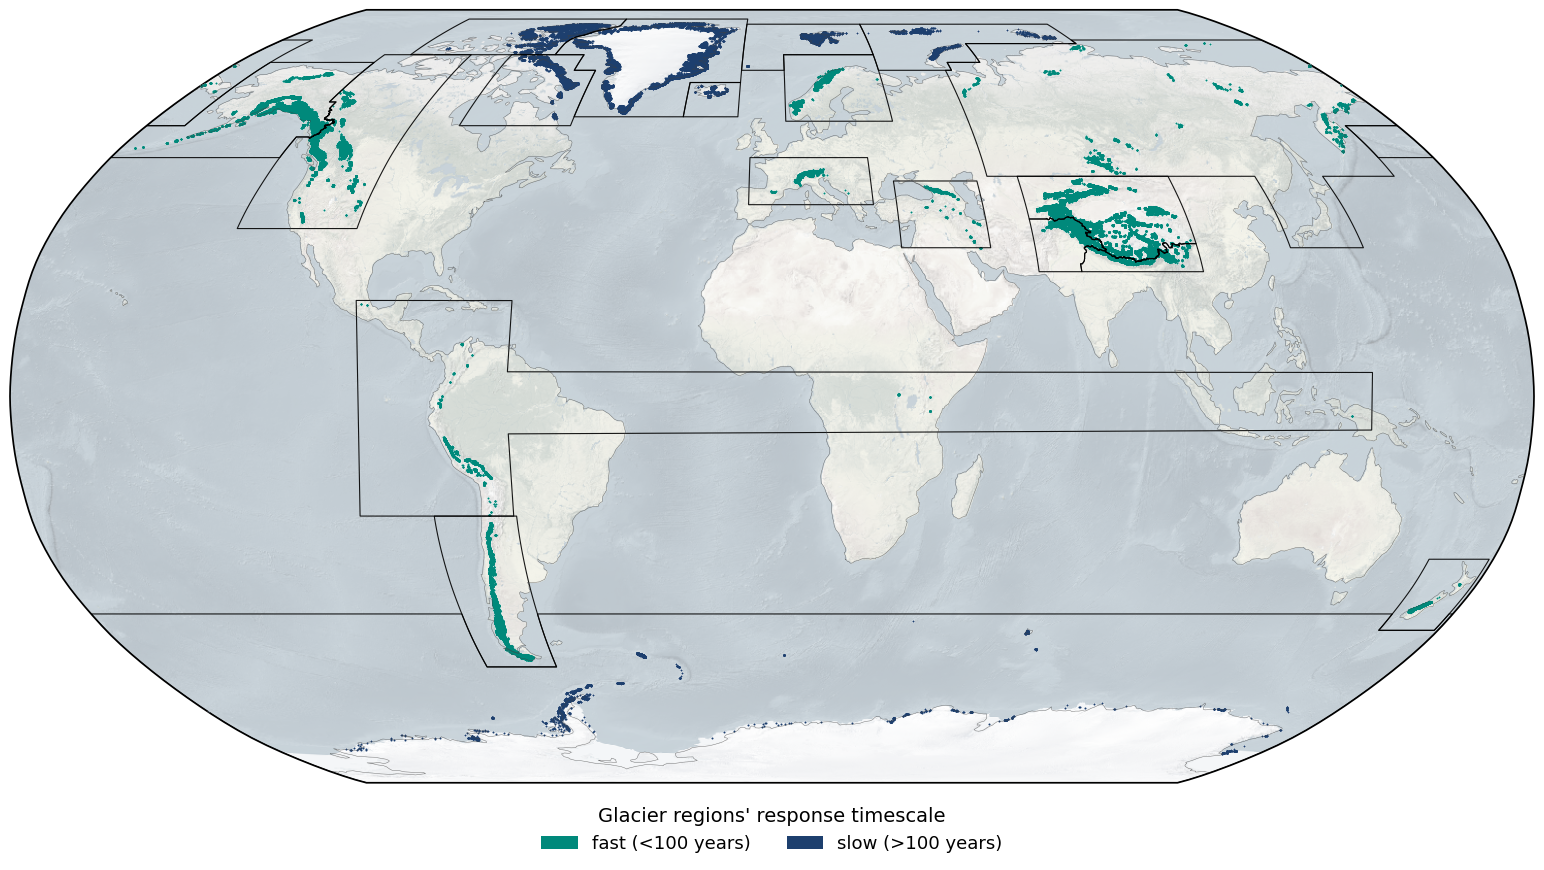

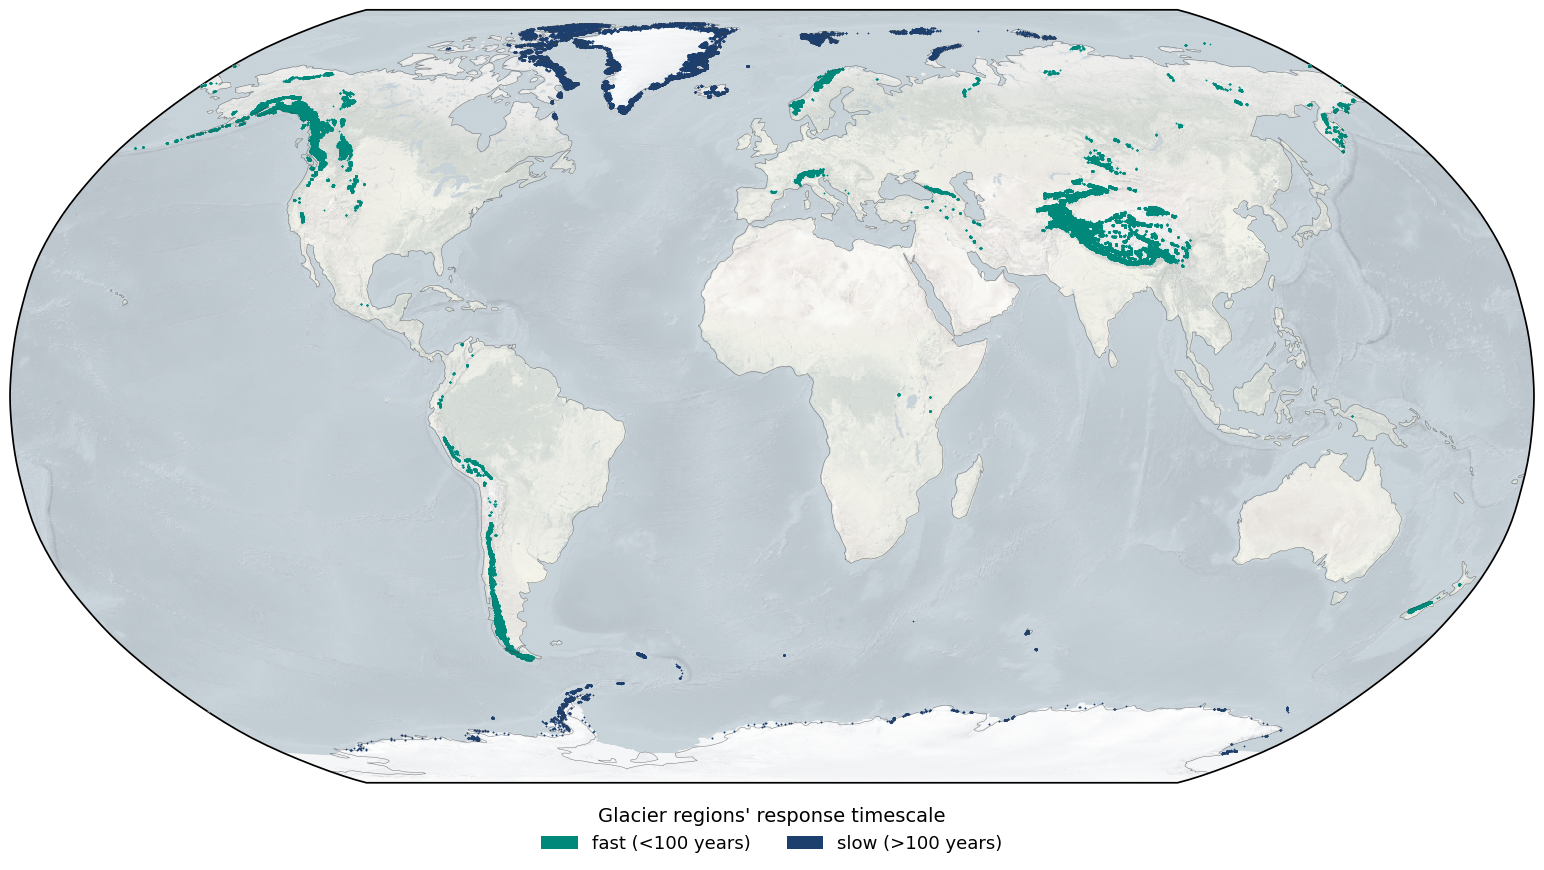

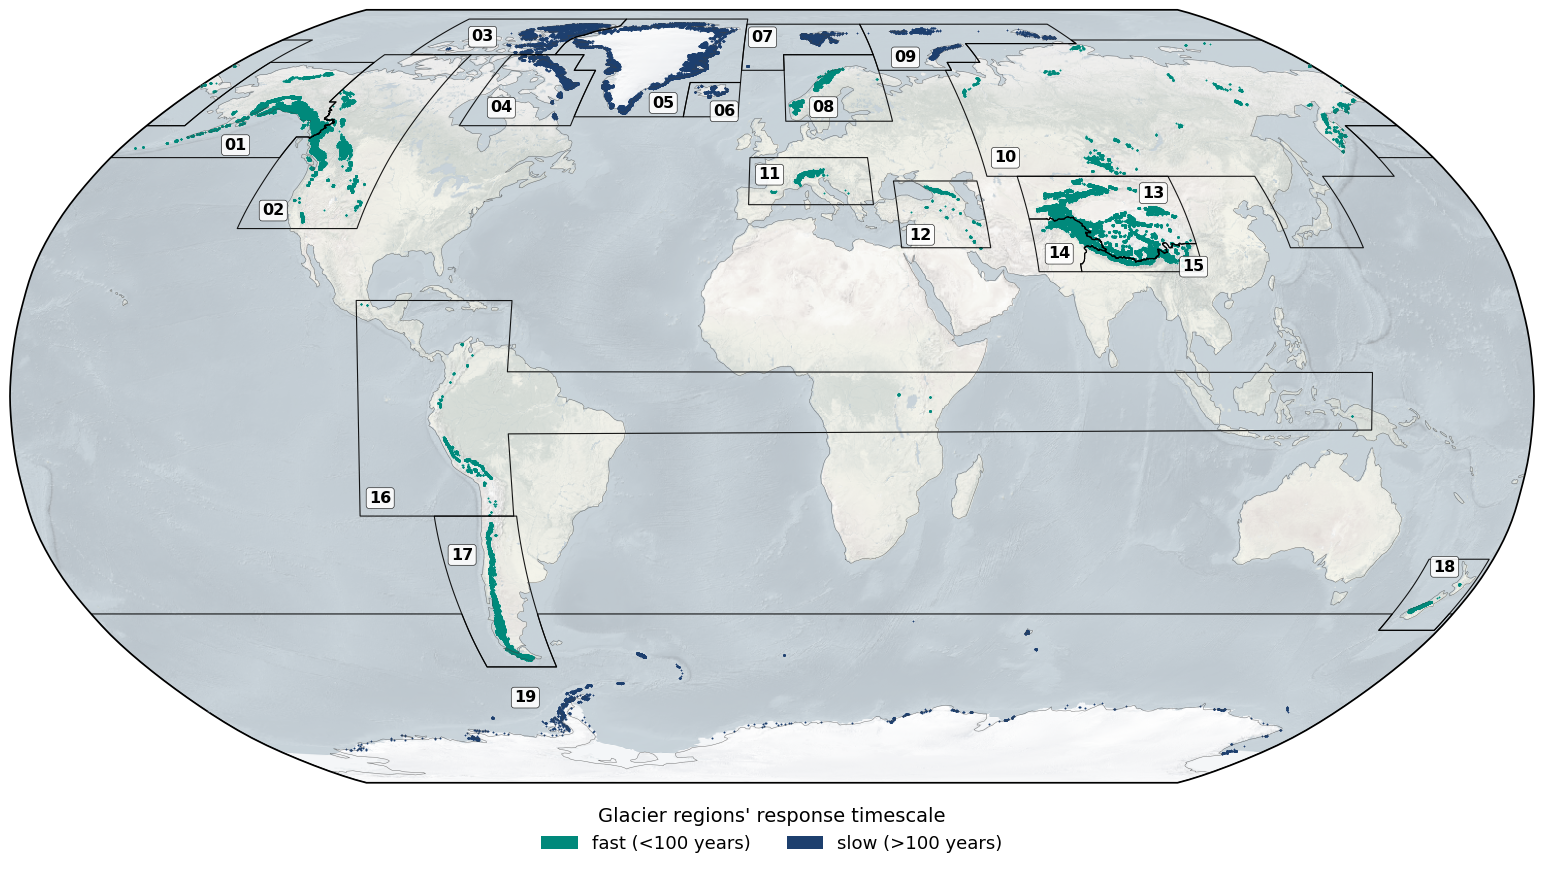

In [23]:
"""Create global RGI maps colored by glacier-response cluster, in three versions:
    1. with region borders
    2. without region borders
    3. with region borders and region numbers

Required objects defined earlier in the analysis/notebook:
    df_rgi6g          Glacier table with CenLon, CenLat, and O1Region columns
    cluster_regions   Dict {"fast": [...], "slow": [...]} with RGI region numbers
    rgi_regions_fn    Path to the RGI region-boundary shapefile
    bck_img           Path to the global background image, or None
"""

import numpy as np
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

import cartopy.feature as cfeature

from shapely.geometry import MultiPoint
from shapely.ops import unary_union, transform as shp_transform
try:
    from shapely import contains_xy
except ImportError:                       # shapely < 2
    from shapely.vectorized import contains as contains_xy


# -----------------------------------------------------------------------------
# Settings
# -----------------------------------------------------------------------------

add_rgi_glaciers = True

# (file suffix, region borders, region numbers)
map_versions = [
    ("borders", True, False),
    ("no_borders", False, False),
    ("borders_numbers", True, True),
]

plt.rc("font", size=12)
fac = 1.3
language = "en"

map_crs = ccrs.Robinson()
data_crs = ccrs.PlateCarree()

# The number of each region is placed INSIDE the region (the polygon that is drawn
# as region border), as close as possible to this corner of the region:
#   "ul" upper left, "ll" lower left, "lr" lower right, "ur" upper right
label_corner = {
    "01": "ul", "03": "ul", "07": "ul", "08": "ul",
    "11": "ul", "12": "ul", "13": "ur", "18": "ul",
    "02": "ll", "04": "ll", "10": "ll", "14": "ll", "16": "ll", "17": "ll",
    "05": "lr", "06": "lr", "15": "lr",
    "09": "ur",   # not in your list, my guess: upper right
}
# Regions not listed above (19) are placed at their densest glacier
# concentration, shifted by (lon, lat) degrees. Negative lon = to the west.
label_shift_deg = {"19": (-15, 0)}

label_fontsize = 11.5
# Within this many label heights from the corner, the label goes to the spot with
# the fewest glaciers underneath (0 = always exactly in the corner).
corner_zone = 1.5
# Gap between a label and the region border (points)
label_inset_pts = 4

# Manual fine-tuning after the automatic placement: (dx, dy) in points,
# +dx = to the right, +dy = up (1 pt is roughly 1/15 of the label height).
label_nudge_pts = {
    "01": (0, -4),      # a bit down
    "05": (0, -3),      # a little down
    "06": (10, -9),
    "08": (3, -5),      # down, slightly right
    "09": (-8, -8),     # down and left
    "12": (0, -8),      # down
    "13": (3, 0),      # right
    "17": (-8, 18),     # left and up
    "15": (8,-5),
    "18": (0,9)
}


# -----------------------------------------------------------------------------
# RGI region names
# -----------------------------------------------------------------------------

d_reg_num_name = {
    "01": "Alaska",
    "02": "Western Canada & USA",
    "03": "Arctic Canada North",
    "04": "Arctic Canada South",
    "05": "Greenland periphery",
    "06": "Iceland",
    "07": "Svalbard and Jan Mayen",
    "08": "Scandinavia",
    "09": "Russian Arctic",
    "10": "North Asia",
    "11": "Central Europe",
    "12": "Caucasus and Middle East",
    "13": "Central Asia",
    "14": "South Asia West",
    "15": "South Asia East",
    "16": "Low Latitudes",
    "17": "Southern Andes",
    "18": "New Zealand",
    "19": "Subantarctic and Antarctic Islands",
}


# -----------------------------------------------------------------------------
# Cluster definitions
# -----------------------------------------------------------------------------

cluster_colors = {
    "fast": "#00897B",  # darker teal
    "slow": "#1D3F6E",  # dark navy
}

cluster_order = [
    "fast",
    "slow",
]

cluster_labels = {
    "fast": "fast (<100 years)",
    "slow": "slow (>100 years)",
}


# -----------------------------------------------------------------------------
# Validate cluster assignments
# -----------------------------------------------------------------------------

assigned_list = [
    region
    for cluster_name in cluster_order
    for region in cluster_regions[cluster_name]
]

assigned_set = set(assigned_list)
expected_set = set(d_reg_num_name)

duplicates = sorted({r for r in assigned_list if assigned_list.count(r) > 1})
missing = sorted(expected_set - assigned_set)
unknown = sorted(assigned_set - expected_set)

if duplicates:
    raise ValueError(f"RGI regions assigned to multiple clusters: {duplicates}")
if missing:
    raise ValueError(f"RGI regions missing from the cluster definitions: {missing}")
if unknown:
    raise ValueError(f"Unknown RGI regions in the cluster definitions: {unknown}")


# -----------------------------------------------------------------------------
# Prepare glacier data
# -----------------------------------------------------------------------------

df_rgi6g_plot = df_rgi6g.copy()

df_rgi6g_plot["O1Region"] = (
    df_rgi6g_plot["O1Region"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(2)
)

df_rgi6g_plot = df_rgi6g_plot.dropna(subset=["CenLon", "CenLat"])

region_to_cluster = {
    region: cluster_name
    for cluster_name, regions in cluster_regions.items()
    for region in regions
}

df_rgi6g_plot["cluster"] = df_rgi6g_plot["O1Region"].map(region_to_cluster)

unclassified = sorted(
    df_rgi6g_plot.loc[df_rgi6g_plot["cluster"].isna(), "O1Region"].unique()
)
if unclassified:
    print(f"Warning: glacier records with unclassified regions: {unclassified}")


# -----------------------------------------------------------------------------
# Region boundaries: read once, detect the coordinate system from the values
# (Robinson metres reach millions, lon/lat degrees stay within +-360)
# -----------------------------------------------------------------------------

boundary_geoms = list(Reader(rgi_regions_fn).geometries())
max_abs_coord = np.abs(np.array([g.bounds for g in boundary_geoms])).max()
boundary_crs = map_crs if max_abs_coord > 360 else data_crs
print(f"Region boundaries: max |coordinate| = {max_abs_coord:.0f} "
      f"-> using {type(boundary_crs).__name__}")


# -----------------------------------------------------------------------------
# Background image: load and mute once
# -----------------------------------------------------------------------------

if bck_img is not None:
    img = imread(bck_img)[..., :3]          # PNG -> floats in 0-1
    gray = img @ [0.299, 0.587, 0.114]
    img_muted = 0.45 + 0.55 * (0.35 * img + 0.65 * gray[..., None])


# -----------------------------------------------------------------------------
# RGI region-number label positions
#
# Each number is positioned at the densest glacier-point concentration within
# its region. This keeps labels close to the actual glacierized area, rather
# than using a polygon bounding-box corner.
# -----------------------------------------------------------------------------

def densest_glacier_label_position(df_region, bins=16):
    """Return a robust label position near the densest glacier concentration."""
    lon = df_region["CenLon"].to_numpy()
    lat = df_region["CenLat"].to_numpy()

    if len(df_region) == 0:
        return None
    if len(df_region) < 10:
        return float(df_region["CenLon"].median()), float(df_region["CenLat"].median())

    # Handle regions crossing the international date line by shifting negative
    # longitudes into the 0-360 range before finding the densest concentration.
    use_shifted_lon = (lon.max() - lon.min()) > 180
    lon_work = lon.copy()
    if use_shifted_lon:
        lon_work = lon_work % 360

    counts, lon_edges, lat_edges = np.histogram2d(lon_work, lat, bins=bins)
    lon_bin, lat_bin = np.unravel_index(np.argmax(counts), counts.shape)

    in_dense_bin = (
        (lon_work >= lon_edges[lon_bin])
        & (lon_work <= lon_edges[lon_bin + 1])
        & (lat >= lat_edges[lat_bin])
        & (lat <= lat_edges[lat_bin + 1])
    )

    label_lon = float(np.median(lon_work[in_dense_bin]))
    label_lat = float(np.median(lat[in_dense_bin]))

    if use_shifted_lon and label_lon > 180:
        label_lon -= 360

    return label_lon, label_lat


# -----------------------------------------------------------------------------
# Region polygons (in map coordinates) for the label placement
#
# The polygon of a region is the border polygon that contains most of its
# glaciers. This does not depend on the attribute names of the shapefile.
# -----------------------------------------------------------------------------

geoms_map = [g if boundary_crs is map_crs else map_crs.project_geometry(g, boundary_crs)
             for g in boundary_geoms]

_xyz = map_crs.transform_points(data_crs, df_rgi6g_plot["CenLon"].to_numpy(),
                                df_rgi6g_plot["CenLat"].to_numpy())
glac_xy = _xyz[:, :2]
glac_ok = np.isfinite(glac_xy).all(axis=1)
glac_region = df_rgi6g_plot["O1Region"].to_numpy()


def mask_in(geom, xy):
    """Boolean mask: which points lie inside geom."""
    out = np.zeros(len(xy), dtype=bool)
    minx, miny, maxx, maxy = geom.bounds
    sel = np.where((xy[:, 0] >= minx) & (xy[:, 0] <= maxx) &
                   (xy[:, 1] >= miny) & (xy[:, 1] <= maxy))[0]
    if len(sel) > 0:
        out[sel] = contains_xy(geom, xy[sel, 0], xy[sel, 1])
    return out


def select_region_polygon(pts):
    """Border polygon(s) of a region, found from the position of its glaciers.

    Border polygons can be nested or overlap (e.g. Iceland inside the Greenland
    polygon), so the SMALLEST polygon that holds (nearly) all glaciers is used.
    Further polygons are only added for glaciers that are not covered yet.
    """
    masks = [mask_in(g, pts) for g in geoms_map]
    n_in = np.array([m.sum() for m in masks])
    if n_in.max() == 0:
        return None, 0.0
    cand = np.where(n_in >= 0.9 * n_in.max())[0]
    main = min(cand, key=lambda i: geoms_map[i].area)
    chosen, covered = [main], masks[main].copy()
    for _ in range(3):
        gain = np.array([(m & ~covered).sum() for m in masks])
        if gain.max() < 0.05 * len(pts):
            break
        cand = np.where(gain >= 0.9 * gain.max())[0]
        nxt = min(cand, key=lambda i: geoms_map[i].area)
        chosen.append(nxt)
        covered |= masks[nxt]
    return unary_union([geoms_map[i] for i in chosen]), covered.mean()


region_polygon = {}
for _reg in sorted(d_reg_num_name):
    _pts = glac_xy[(glac_region == _reg) & glac_ok]
    if len(_pts) == 0:
        continue
    _poly, _cov = select_region_polygon(_pts)
    if _poly is None or _cov < 0.5:
        print(f"Warning: no border polygon found for region {_reg}, "
              f"using the convex hull of its glaciers instead")
        _poly = MultiPoint(_pts[::max(1, len(_pts) // 5000)]).convex_hull
    elif _cov < 0.95:
        print(f"Note: region {_reg}: {100 * _cov:.0f}% of its glaciers lie inside the "
              f"selected border polygon(s)")
    region_polygon[_reg] = _poly


# -----------------------------------------------------------------------------
# Label placement inside the regions
# -----------------------------------------------------------------------------

def place_region_numbers(fig, ax):
    """Add the region numbers; needs a final figure layout (call tight_layout first)."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    box_style = {"boxstyle": "round,pad=0.18", "facecolor": "white",
                 "edgecolor": "black", "linewidth": 0.45, "alpha": 0.88}

    # size of a two-digit label in pixels (all labels have the same size)
    t = ax.text(0.5, 0.5, "00", transform=ax.transAxes, fontsize=label_fontsize,
                fontweight="bold", bbox=box_style)
    bb = t.get_window_extent(renderer)
    frame_px = 0.18 * label_fontsize * fig.dpi / 72
    w, h = bb.width + 2 * frame_px, bb.height + 2 * frame_px
    t.remove()

    def to_display(x, y, z=None):        # z: some cartopy geometries carry a z coordinate
        return tuple(ax.transData.transform(np.column_stack([np.asarray(x), np.asarray(y)])).T)

    # number of glaciers in any pixel box via a summed-area table
    W, H = int(np.ceil(fig.bbox.width)), int(np.ceil(fig.bbox.height))
    gd = ax.transData.transform(glac_xy[glac_ok])
    hist = np.histogram2d(gd[:, 0], gd[:, 1], bins=[np.arange(W + 1), np.arange(H + 1)])[0]
    sat = np.zeros((W + 1, H + 1))
    sat[1:, 1:] = hist.cumsum(0).cumsum(1)

    def n_glaciers(x1, y1, x2, y2):
        x1, x2 = np.clip(np.floor(x1), 0, W).astype(int), np.clip(np.ceil(x2), 0, W).astype(int)
        y1, y2 = np.clip(np.floor(y1), 0, H).astype(int), np.clip(np.ceil(y2), 0, H).astype(int)
        return sat[x2, y2] - sat[x1, y2] - sat[x2, y1] + sat[x1, y1]

    def overlaps(x1, y1, x2, y2, other, margin=2):
        return not (x2 + margin < other[0] or other[2] + margin < x1 or
                    y2 + margin < other[1] or other[3] + margin < y1)

    placed = {}   # region -> (x1, y1, x2, y2, tier)

    def box_at(cx, cy):
        return cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2

    # regions without a corner (19): densest glacier concentration, shifted
    for r in sorted(d_reg_num_name):
        if r in label_corner or r not in region_polygon:
            continue
        lon, lat = densest_glacier_label_position(
            df_rgi6g_plot.loc[df_rgi6g_plot["O1Region"] == r])
        dlon, dlat = label_shift_deg.get(r, (0, 0))
        cx, cy = ax.transData.transform(map_crs.transform_point(lon + dlon, lat + dlat, data_crs))
        placed[r] = (*box_at(cx, cy), 0)

    offsets = [(-w / 2, -h / 2), (0, -h / 2), (w / 2, -h / 2), (-w / 2, 0), (0, 0),
               (w / 2, 0), (-w / 2, h / 2), (0, h / 2), (w / 2, h / 2)]
    step = 3  # px
    inset_px = label_inset_pts * fig.dpi / 72
    globe = shp_transform(to_display, map_crs.domain).buffer(-inset_px)  # keep labels on the map

    for r in sorted(label_corner):
        if r not in region_polygon:
            continue
        poly_raw = shp_transform(to_display, region_polygon[r]).intersection(globe)
        poly_in = poly_raw.buffer(-inset_px)          # gap to the region border
        minx, miny, maxx, maxy = poly_raw.bounds
        CX, CY = np.meshgrid(np.arange(minx, maxx + step, step), np.arange(miny, maxy + step, step))
        CX, CY = CX.ravel(), CY.ravel()

        # tier 1: whole label inside the region (with a gap to the border if possible);
        # tier 2: label centre inside (region smaller than the label)
        ok, tier = None, None
        for poly_try in (poly_in, poly_raw):
            if poly_try.is_empty:
                continue
            full = np.all([contains_xy(poly_try, CX + dx, CY + dy) for dx, dy in offsets], axis=0)
            if full.any():
                ok, tier = full, 1
                break
        if ok is None:
            ctr = contains_xy(poly_raw, CX, CY)
            if ctr.any():
                ok, tier = ctr, 2
            else:
                p = poly_raw.representative_point()
                placed[r] = (*box_at(p.x, p.y), 3)
                continue

        # not on top of already placed labels (if avoidable)
        clash = np.zeros(len(CX), dtype=bool)
        for other in placed.values():
            x1, y1, x2, y2 = box_at(CX, CY)
            clash |= ~((x2 + 2 < other[0]) | (other[2] + 2 < x1) |
                       (y2 + 2 < other[1]) | (other[3] + 2 < y1))
        if (ok & ~clash).any():
            ok = ok & ~clash

        # distance of the label corner to the region corner
        corner = label_corner[r]
        lx = CX - w / 2 if corner in ("ul", "ll") else CX + w / 2
        ly = CY + h / 2 if corner in ("ul", "ur") else CY - h / 2
        rx = minx if corner in ("ul", "ll") else maxx
        ry = maxy if corner in ("ul", "ur") else miny
        dist = np.hypot(lx - rx, ly - ry)

        # within the corner zone: fewest glaciers underneath, then closest to the corner
        idx = np.where(ok)[0]
        idx = idx[dist[idx] <= dist[idx].min() + corner_zone * h]
        x1, y1, x2, y2 = box_at(CX[idx], CY[idx])
        best = idx[np.lexsort((dist[idx], n_glaciers(x1, y1, x2, y2)))[0]]
        placed[r] = (*box_at(CX[best], CY[best]), tier)

    # manual fine-tuning
    for r, (dx, dy) in label_nudge_pts.items():
        if r in placed:
            x1, y1, x2, y2, tier = placed[r]
            sx, sy = dx * fig.dpi / 72, dy * fig.dpi / 72
            placed[r] = (x1 + sx, y1 + sy, x2 + sx, y2 + sy, tier)

    # report
    print("Region numbers:")
    for r in sorted(placed):
        x1, y1, x2, y2, tier = placed[r]
        n_gl = int(n_glaciers(np.array([x1]), np.array([y1]), np.array([x2]), np.array([y2]))[0])
        notes = []
        if tier == 2:
            notes.append("region smaller than the label, label sticks out")
        if tier == 3:
            notes.append("region very small, label at a representative point")
        for o, ob in placed.items():
            if o != r and overlaps(x1, y1, x2, y2, ob, margin=0):
                notes.append(f"overlaps label {o}")
        print(f"  {r} {label_corner.get(r, '--'):>2s}: {n_gl:5d} glaciers under the label"
              + (f"   <- {'; '.join(notes)}" if notes else ""))

    inv = ax.transData.inverted()
    for r, (x1, y1, x2, y2, tier) in placed.items():
        xd, yd = inv.transform(((x1 + x2) / 2, (y1 + y2) / 2))
        ax.annotate(r, xy=(xd, yd), xycoords="data", ha="center", va="center",
                    fontsize=label_fontsize, fontweight="bold", color="black",
                    bbox=box_style, zorder=6, annotation_clip=False)


# -----------------------------------------------------------------------------
# One figure per version
# -----------------------------------------------------------------------------

for version, add_region_boundaries, add_region_numbers in map_versions:

    output_file = f"RGI_response_timescale_cluster_worldmap_{version}_{language}.png"
    output_file2 = f"RGI_response_timescale_cluster_worldmap_{version}_{language}.pdf"

    fig = plt.figure(figsize=(12 * fac, 7 * fac))
    ax_background = fig.add_subplot(1, 1, 1, projection=map_crs)
    ax_background.set_global()

    # Background
    if bck_img is not None:
        ax_background.imshow(
            img_muted,
            origin="upper",
            transform=data_crs,
            extent=[-180, 180, -90, 90],
            zorder=0,
        )
    else:
        ax_background.set_facecolor("#DCEAF4")
        ax_background.add_feature(
            cfeature.LAND,
            facecolor="#F2F2F2",
            edgecolor="none",
            zorder=0,
        )
        ax_background.add_feature(
            cfeature.OCEAN,
            facecolor="#DCEAF4",
            edgecolor="none",
            zorder=0,
        )

    # Glacier points colored by cluster
    if add_rgi_glaciers:
        # Draw unclassified records only in faint grey. Classified glaciers are not
        # covered by a grey base layer, so their cluster colors remain saturated.
        df_unclassified = df_rgi6g_plot.loc[df_rgi6g_plot["cluster"].isna()]

        if not df_unclassified.empty:
            ax_background.scatter(
                df_unclassified["CenLon"].values,
                df_unclassified["CenLat"].values,
                color="0.65",
                s=1.0,
                alpha=0.45,
                linewidths=0,
                transform=data_crs,
                rasterized=True,
                zorder=2,
            )

        for cluster_name in cluster_order:
            region_numbers = cluster_regions[cluster_name]
            df_cluster = df_rgi6g_plot.loc[
                df_rgi6g_plot["O1Region"].isin(region_numbers)
            ]

            # White underlay creates a narrow halo against the map background.
            ax_background.scatter(
                df_cluster["CenLon"].values,
                df_cluster["CenLat"].values,
                color="white",
                s=5.0,
                alpha=0.70,
                linewidths=0,
                transform=data_crs,
                rasterized=True,
                zorder=2.8,
            )

            ax_background.scatter(
                df_cluster["CenLon"].values,
                df_cluster["CenLat"].values,
                color=cluster_colors[cluster_name],
                s=2.2,
                alpha=1.0,
                linewidths=0,
                transform=data_crs,
                rasterized=True,
                zorder=3,
            )

    # Region boundaries
    if add_region_boundaries:
        region_boundaries = ShapelyFeature(
            boundary_geoms,
            boundary_crs,
            facecolor="none",
            edgecolor="black",
            linewidth=0.8,
            alpha=0.9,
        )
        ax_background.add_feature(region_boundaries, zorder=4)

    # Coastlines and legend
    ax_background.coastlines(
        resolution="110m",
        color="0.25",
        linewidth=0.35,
        alpha=0.7,
        zorder=4,
    )

    legend_handles = [
        mpatches.Patch(
            facecolor=cluster_colors[cluster_name],
            edgecolor="none",
            label=cluster_labels[cluster_name],
        )
        for cluster_name in cluster_order
    ]

    ax_background.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.01),  # centred, just below the map
        ncol=2,
        title="Glacier regions' response timescale",
        fontsize=13,
        title_fontsize=14,
        frameon=False,
    )

    plt.tight_layout()

    # Region numbers (after the layout is final, so overlaps can be checked)
    if add_region_numbers:
        place_region_numbers(fig, ax_background)

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    
    plt.savefig(
        output_file2,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    print(f"Saved cluster map to: {output_file}")